# Step 1 • Getting to know MAN TruckScenes (min)

Ten 20-second scenes recorded by a MAN truck with 6 lidars, 6 radars and 4 cameras.
This notebook answers nine questions before anything is built on the data:

1. What is in every column?
2. How big is each table?
3. How do the tables link?
4. What are the 10 scenes?
5. How often does each sensor record?
6. What objects are labeled?
7. How do lidar and radar see objects at different distances?
8. How did the truck move, and what is the strongest braking?
9. Three scenes show a top speed of 0: did the truck really stand still?

Data: MAN TruckScenes, CC By-NC-SA 4.0 (non-commercial, with credit). Not stored in this repo.

In [31]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd

DATA = "../data/man-truckscenes/v1.2-mini"  # the 14 tables, one JSON file each (scripts/get_metadata.sh)
TABLES = [
    "attribute",
    "calibrated_sensor",
    "category",
    "ego_motion_cabin",
    "ego_motion_chassis",
    "ego_pose",
    "instance",
    "sample",
    "sample_annotation",
    "sample_data",
    "scene",
    "sensor",
    "visibility",
    "weather_annotation",
]

pd.set_option("display.max_rows", 200)  # show all 106 rows of the column table, not the first and last 5
db = duckdb.connect()  # an in-memory database: nothing is copied, the views read the JSON files
for t in TABLES:
    db.sql(f"CREATE VIEW {t} AS SELECT * FROM read_json_auto('{DATA}/{t}.json')")


def q(query: str) -> pd.DataFrame:
    """Run SQL on the views and get a pandas table back."""
    return db.sql(query).df()

## 1. What is in every column?

In [32]:
cols = pd.concat([q(f"SUMMARIZE {t}").assign(table_name=t) for t in TABLES], ignore_index=True)

# SUMMARIZE counts NULLs only; an empty link here is '' (empty text), so count those too
blank = []
for t in TABLES:
    for c in q(f"DESCRIBE {t}").query("column_type == 'VARCHAR'").column_name:
        blank.append((t, c, q(f"SELECT count(*) AS n FROM {t} WHERE \"{c}\" = ''").n[0]))
cols = cols.merge(pd.DataFrame(blank, columns=["table_name", "column_name", "blank"]), how="left")

print(f"{len(cols)} columns in {len(TABLES)} tables")
cols[["table_name", "column_name", "column_type", "count", "blank", "min", "max", "approx_unique"]]

106 columns in 14 tables


,table_name,column_name,column_type,count,blank,min,max,approx_unique
0,attribute,token,VARCHAR,11,0.0,0b54e4f5fcc1437fb0ce9fa766744295,eefd82c9b2f144e2b1c61a432254cff2,11
1,attribute,name,VARCHAR,11,0.0,cycle.with_rider,vehicle.stopped,11
2,attribute,description,VARCHAR,11,0.0,The human is moving.,"When the traffic sign is mounted on a pole, ty...",11
3,calibrated_sensor,token,VARCHAR,18,0.0,1b717cbfe9c34165b18c28a8e9bb746a,f994daad50a14ac49f1468d66eb8db62,18
4,calibrated_sensor,sensor_token,VARCHAR,18,0.0,0785ec5f7a5e4c93a99fea2ad781783d,fe19aa64da874708a8cd417103e7cdc7,18
5,calibrated_sensor,translation,DOUBLE[],18,NaN,"[-0.8620346128, 0.0, 0.5694556851]","[5.2589504, 1.2266158, 2.0126382]",18
6,calibrated_sensor,rotation,DOUBLE[],18,NaN,"[-0.004295317692716905, 0.8655123078754067, -0...","[0.9999486962359652, 0.00125156170995682, 0.00...",18
7,calibrated_sensor,camera_intrinsic,DOUBLE[][],18,NaN,[],"[[640.0, 0.0, 960.0], [0.0, 640.0, 520.0], [0....",2
8,category,token,VARCHAR,27,0.0,01262314d8614a6ba620363d14adeefc,fec744eb30e5499ab654c8e9576658b0,26
9,category,name,VARCHAR,27,0.0,animal,vehicle.truck,27


## 2. How big is each table?

In [33]:
q(" UNION ALL ".join(f"SELECT '{t}' AS table_name, count(*) AS rows FROM {t}" for t in TABLES)).sort_values(
    "rows", ascending=False
)

,table_name,rows
9,sample_data,43556
8,sample_annotation,25750
5,ego_pose,20116
3,ego_motion_cabin,20090
4,ego_motion_chassis,20089
6,instance,1094
7,sample,400
2,category,27
1,calibrated_sensor,18
11,sensor,18


## 3. How do the tables link? One key frame and its 16 sensor readings

In [34]:
q("""
SELECT s.modality, s.channel, d.fileformat
FROM sample_data AS d
JOIN calibrated_sensor AS c ON d.calibrated_sensor_token = c.token  -- which mounted sensor made this reading
JOIN sensor AS s ON c.sensor_token = s.token                          -- its name and type
WHERE d.is_key_frame AND d.sample_token = (SELECT first_sample_token FROM scene LIMIT 1)
ORDER BY s.modality, s.channel
""")

,modality,channel,fileformat
0,camera,CAMERA_LEFT_BACK,jpg
1,camera,CAMERA_LEFT_FRONT,jpg
2,camera,CAMERA_RIGHT_BACK,jpg
3,camera,CAMERA_RIGHT_FRONT,jpg
4,lidar,LIDAR_LEFT,pcd
5,lidar,LIDAR_REAR,pcd
6,lidar,LIDAR_RIGHT,pcd
7,lidar,LIDAR_TOP_FRONT,pcd
8,lidar,LIDAR_TOP_LEFT,pcd
9,lidar,LIDAR_TOP_RIGHT,pcd


In [35]:
# all 18 seonsors with the exact names the data uses (the 2 motion sensors have no ros in sample_data)
q("SELECT modality, channel FROM sensor ORDER BY modality, channel")

,modality,channel
0,camera,CAMERA_LEFT_BACK
1,camera,CAMERA_LEFT_FRONT
2,camera,CAMERA_RIGHT_BACK
3,camera,CAMERA_RIGHT_FRONT
4,imu,XSENSE_CABIN
5,imu,XSENSE_CHASSIS
6,lidar,LIDAR_LEFT
7,lidar,LIDAR_REAR
8,lidar,LIDAR_RIGHT
9,lidar,LIDAR_TOP_FRONT


## 4. What are the 10 scenes?|

In [36]:
# q("DESCRIBE scene")[["column_name", "column_type"]]  # eda
# q("SELECT * FROM scene LIMIT 1").T  # eda, turn the table on its side showing each column as line with its values shown
scenes = q("SELECT name, nbr_samples, description FROM scene")
tags = pd.DataFrame(
    [dict(part.split(".", 1) for part in d.split(";")) for d in scenes.description]
)  # weather.rain -> weather: rain
tags.insert(0, "samples", scenes.nbr_samples)
tags

,samples,weather,area,daytime,season,lighting,structure,construction
0,40,clear,terminal,noon,autumn,illuminated,regular,unchanged
1,40,clear,highway,evening,autumn,dark,overpass,unchanged
2,40,overcast,city,noon,winter,illuminated,bridge,unchanged
3,40,overcast,highway,noon,summer,illuminated,regular,unchanged
4,40,overcast,highway,morning,summer,illuminated,regular,roadworks
5,40,rain,terminal,morning,summer,illuminated,regular,unchanged
6,40,clear,city,noon,winter,twilight,regular,unchanged
7,40,snow,city,noon,autumn,illuminated,regular,unchanged
8,40,rain,highway,noon,autumn,illuminated,regular,unchanged
9,40,clear,city,noon,winter,other_lighting,regular,unchanged


## 5. How often does each sensor record?

In [37]:
seconds = q(
    "SELECT sum(span) AS s FROM (SELECT (max(timestamp) - min(timestamp)) / 1e6 As span FROM sample GROUP BY scene_token)"
).s[0]
rates = q("""
SELECT s.modality, s.channel, count(*) AS readings
FROM sample_data AS d
JOIN calibrated_sensor AS c ON d.calibrated_sensor_token = c.token
JOIN sensor AS s ON c.sensor_token = s.token
GROUP BY ALL ORDER BY s.modality, s.channel
""")
rates["per_second"] = (rates.readings / seconds).round(1)
print(f"{seconds:.0f} seconds of driving in all")
rates

195 seconds of driving in all


,modality,channel,readings,per_second
0,camera,CAMERA_LEFT_BACK,2010,10.3
1,camera,CAMERA_LEFT_FRONT,2016,10.3
2,camera,CAMERA_RIGHT_BACK,2010,10.3
3,camera,CAMERA_RIGHT_FRONT,2010,10.3
4,lidar,LIDAR_LEFT,2010,10.3
5,lidar,LIDAR_REAR,2005,10.3
6,lidar,LIDAR_RIGHT,2018,10.3
7,lidar,LIDAR_TOP_FRONT,2010,10.3
8,lidar,LIDAR_TOP_LEFT,2010,10.3
9,lidar,LIDAR_TOP_RIGHT,2018,10.3


# 6. What objects are labeled?

In [38]:
q("""
SELECT c.name AS class, count(*) AS objects, sum(i.nbr_annotations) AS boxes
FROM instance AS i JOIN category AS c ON i.category_token = c.token
GROUP BY ALL ORDER BY boxes DESC
""")

,class,objects,boxes
0,vehicle.car,561,11811.0
1,static_object.traffic_sign,218,6666.0
2,vehicle.truck,96,2230.0
3,vehicle.trailer,66,1468.0
4,human.pedestrian.adult,41,1000.0
5,movable_object.trafficcone,55,857.0
6,vehicle.bus.rigid,12,379.0
7,vehicle.ego_trailer,9,360.0
8,vehicle.train,5,200.0
9,human.pedestrian.construction_worker,5,172.0


## 7. How do lidar and radar see objects at different distances?

In [39]:
boxes = q("""
SELECT a.num_lidar_pts AS lidar, a.num_radar_pts AS radar, v.level AS visibility,
       sqrt(power(a.translation[1] - p.translation[1], 2) + power(a.translation[2] - p.translation[2], 2)) AS meters
FROM sample_annotation AS a
JOIN sample AS s ON a.sample_token = s.token
JOIN ego_pose AS p ON s.ego_pose_token = p.token  -- where the truck was at that moment
JOIN visibility AS v ON a.visibility_token = v.token
""")
boxes["band"] = pd.cut(boxes.meters, [0, 25, 50, 75, 100, 150, 200, 300])
by_band = boxes.groupby("band", observed=True).agg(
    boxes=("lidar", "size"),
    median_lidar_points=("lidar", "median"),
    share_with_radar=("radar", lambda x: (x > 0).mean()),
)
by_band.round(2)

,boxes,median_lidar_points,share_with_radar
band,,,
"(0, 25]",4032,805.5,0.78
"(25, 50]",6431,109.0,0.59
"(50, 75]",4948,34.0,0.46
"(75, 100]",3540,17.0,0.37
"(100, 150]",4426,9.0,0.27
"(150, 200]",1935,6.0,0.19
"(200, 300]",438,5.0,0.00


## 8. How did the truck move, and what is the strongest braking?

In [40]:
motion = q("""
WITH span AS (SELECT scene_token, min(timestamp) AS t0, max(timestamp) AS t1 FROM sample GROUP BY scene_token)
SELECT sc.name AS scene, (m.timestamp - span.t0) / 1e6 AS t, m.vx AS speed, m.ax AS accel
FROM ego_motion_chassis AS m
JOIN span ON m.timestamp BETWEEN span.t0 AND span.t1
JOIN scene AS sc ON sc.token = span.scene_token
ORDER by scene, t
""")
motion.groupby("scene").agg(top_speed=("speed", "max"), lowest_accel=("accel", "min")).round(2)

,top_speed,lowest_accel
scene,,
scene-0044384af3d8494e913fb8b14915239e-3,3.44,-3.21
scene-13f4b71b1bd04a9e88747ad8f58a3f67-4,25.24,-2.76
scene-23160c4bff134cdd86b96ee822b4aca9-14,0.00,-0.83
scene-3195e3bfd1de4f9ba82f874790c7856c-15,23.71,-5.88
scene-3f542f89ec5241b6a4e30ca743adcf34-29,17.75,-2.74
scene-6be74229febb4aad9e7ae1a37217b231-4,0.02,-0.55
scene-a6a87db5125846bda72ccfc9931ee153-11,10.63,-1.55
scene-b13542304b244af585a646082c57a079-1,6.01,-1.46
scene-b201f6e737e34c2d87830fc1e2911516-6,0.00,-1.02


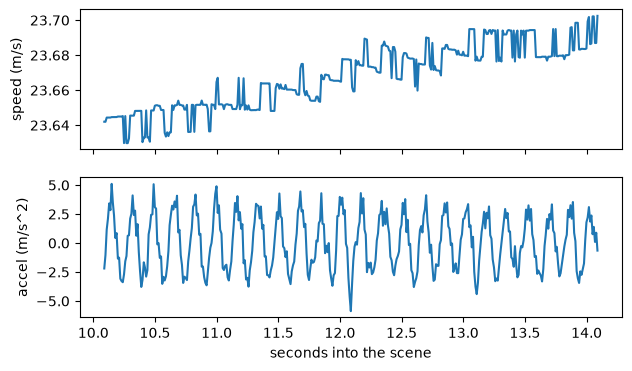

lowest accel -5.88 m/s^2 at 12.1 s; speed went from 23.64 to 23.70 m/s in those 4 seconds


In [41]:
worst = motion.loc[motion.accel.idxmin()]  # the most negative acceleration (the hardest brake) in all 10 scenes
around = motion[(motion.scene == worst.scene) & motion.t.between(worst.t - 2, worst.t + 2)]
fig, ax = plt.subplots(2, 1, figsize=(7, 4), sharex=True)
ax[0].plot(around.t, around.speed)
ax[0].set_ylabel("speed (m/s)")
ax[1].plot(around.t, around.accel)
ax[1].set(ylabel="accel (m/s^2)", xlabel="seconds into the scene")
plt.show()
print(
    f"lowest accel {worst.accel:.2f} m/s^2 at {worst.t:.1f} s; speed went from "
    f"{around.speed.iloc[0]:.2f} to {around.speed.iloc[-1]:.2f} m/s in those 4 seconds"
)

### Check: was the lowest accel a real brake?
- The raw minimum (−5.88 m/s² at 12.1 s) is **not a real brake**: accel jumped from +2.8 to −5.9 and back in about 0.05 seconds (5 rows), and the speed stayed at 23.6 to 23.7 m/s.
- It looks like vibration (the truck shaking). Raw accel is recorded 100 times a second and is noisy.
- In these 10 scenes, after a half-second average no reading below −3 m/s² is left below −2 (Code cell 20d).
- **Working choice for now, not a final rule:** average accel over half a second (50 rows), then confirm with the speed. Re-check the window on the full data (Step 2b) and on any new dataset or truck.

In [42]:
# half-second average of accel, worked out inside each scene (10 sample scenes)
motion["accel_05s"] = motion.groupby("scene").accel.transform(lambda a: a.rolling(50, center=True).mean())

real = motion.loc[motion.accel_05s.idxmin()]  # strongest braking after smoothing
print(f"raw minimum:        {worst.accel:.2f} m/s² at {worst.t:.1f} s, {worst.scene}")
print(f"0.5-second average: {real.accel_05s:.2f} m/s² at {real.t:.1f} s, {real.scene}")

raw minimum:        -5.88 m/s² at 12.1 s, scene-3195e3bfd1de4f9ba82f874790c7856c-15
0.5-second average: -1.16 m/s² at 3.9 s, scene-b13542304b244af585a646082c57a079-1


In [43]:
around_real = motion[(motion.scene == real.scene) & motion.t.between(real.t - 2, real.t + 2)]
print(f"speed: {around_real.speed.iloc[0]:.2f} → {around_real.speed.iloc[-1]:.2f} m/s in those 4 seconds")

speed: 5.59 → 2.60 m/s in those 4 seconds


In [44]:
spikes = motion[motion.accel < -3]  # every reading below -3 m/s² in the 10 scenes
print(f"{len(spikes)} readings below -3; {(spikes.accel_05s < -2).sum()} still below -2 after the half-second average")

230 readings below -3; 0 still below -2 after the half-second average


## 9. Three scenes show a top speed of 0: did the truck really stand still?

The chassis speed is one sensor. Two more sources say how fast the truck went: the cab's own motion sensor, and the truck's position (`ego_pose`), where speed = distance driven / time.

In [45]:
# finding scene time windows
span = "SELECT scene_token, min(timestamp) AS t0, max(timestamp) AS t1 FROM sample GROUP BY scene_token"

# pulling truck positions
# the truck's position over time; ego_pose.timestamp is read as DOUBLE (some values are written as 123.0), so cast it
pose = q(f"""
SELECT span.scene_token, CAST(p.timestamp AS BIGINT) AS ts, p.translation[1] AS x, p.translation[2] AS y
FROM ego_pose AS p JOIN ({span}) AS span ON CAST(p.timestamp AS BIGINT) BETWEEN span.t0 AND span.t1
ORDER BY span.scene_token, ts
""")
# calculating distance traveled (meters)
step = pose.groupby("scene_token")[["x", "y"]].diff()  # meters moved since the previous position
pose["meters"] = (step.x**2 + step.y**2) ** 0.5

# computing average speed from gps
speeds = pose.groupby("scene_token").agg(meters=("meters", "sum"), t0=("ts", "min"), t1=("ts", "max"))
speeds["by_position"] = speeds.meters / ((speeds.t1 - speeds.t0) / 1e6)
# adding sensor speeds & environmental tags
for table in ["ego_motion_cabin", "ego_motion_chassis"]:
    v = q(
        f"SELECT span.scene_token, avg(m.vx) AS v FROM {table} AS m JOIN ({span}) AS span ON m.timestamp BETWEEN span.t0 AND span.t1 GROUP BY ALL"
    )
    speeds[table.removeprefix("ego_motion_")] = v.set_index("scene_token").v

tags = q("SELECT token AS scene_token, description FROM scene").set_index("scene_token").description.str.split(";")
speeds["scene"] = tags.str[1].str.removeprefix("area.") + ", " + tags.str[0].str.removeprefix("weather.")
speeds[["scene", "by_position", "cabin", "chassis"]].round(2).sort_values("by_position")

,scene,by_position,cabin,chassis
scene_token,,,,
9fb76bae00124c85aaf4d6d0e4dbf194,"terminal, rain",0.04,0.00,0.00
d0b02e67e97a435192bf43f7bb0f902c,"city, snow",1.93,1.92,1.94
044c648ac12345f1aedf33c9f91cdc5a,"terminal, clear",2.90,2.86,2.87
073e6bb18188424ea9981e3845df54a6,"city, clear",5.28,5.23,5.23
81f0a41d0a7a44e0ae8f8ea0ade95fdf,"city, overcast",5.91,5.86,0.00
b13b6eb5c4bf4479a631372af53baf28,"highway, rain",6.82,6.79,0.00
38d4ba33fce94499be34f32d245113ed,"city, clear",7.28,7.27,7.25
fb0a3d4e84c74b07ba0997891ed12f0b,"highway, overcast",17.49,17.43,17.44
b71e2b6ba3fa4279b36bfd4b9720251e,"highway, overcast",23.78,23.64,23.64


## What this tells us

1. Every key frame has all 16 sensor readings: 6 lidar, 6 radar, 4 camera. Between key frames there are more readings: cameras and lidars about 10 per second, radars about 20.
2. 25,750 boxes on 1,094 tracked objects; cars and traffic signs are most of them. `vehicle.ego_trailer` is the truck's own trailer: it is not another road user.
3. Lidar points fall fast with distance (hundreds up close, about 5 past 200 m), and radar sees a box less often the farther it is (none past 200 m).
4. The lowest acceleration, −5.9 m/s², is **not** a hard brake: the speed stays about 23.7 m/s. It is vibration in the sensor, so a braking rule must look at the change in speed, not single acceleration readings (Step 3). Averaged over half a second, the real strongest braking is −1.16 m/s², and the speed confirms it (5.6 → 2.6 m/s). The half second is a working choice from 10 scenes: re-check it in Step 2b.
5. Only one scene really stands still (the rain terminal). In two more (the bridge in the city, and the rainy highway) the chassis speed reads 0.00 for all 20 seconds while the truck drove about 6 m/s by its position and by the cab sensor. So speed comes from the cab sensor or the position, never from the chassis alone, and Step 2 checks the three against each other.
6. 106 columns in 14 tables. Empty links are '' (empty text), not NULL; `ego_pose.timestamp` is read as a decimal and must be cast before joining on time; temperature is in kelvin. Every column is in docs/data-dictionary.md.

Open questions for Step 2: do all boxes belong to real frames and tracks? Do timestamps only go forward? Are there gaps in the truck's motion? Do the three speed sources agree?